# Customer Churn Analysis & Customer Intelligence

**Tools:** SQLite, Python, Pandas, NumPy, Matplotlib  
**Goal:** Understand customer churn, identify customer segments with elevated churn, and translate findings into practical customer-retention actions.

> **Data note:** This notebook reads customer churn data from `customer_churn.db`. Make sure the database exists at the path configured in the **Data import** code cell before running the notebook.

---


In [1]:
# Churn Analysis and Customer Intelligence

In [1]:
# import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sqlite3

In [2]:
# Data import

# Connect to SQLite database
conn = sqlite3.connect(
    r"C:\Users\dell\Downloads\customer_churn.db"
)

# sql query to Get all table names       # we use """ code for writing the code in multiple lines 
sql_query = """                
         SELECT name 
         FROM sqlite_master 
         where type ='table';
"""
# read sql query in pandas
tables = pd.read_sql(sql_query , conn)

# create dataframe for each table
for table_name in tables['name']:
    df = pd.read_sql(f"SELECT * FROM {table_name}",conn)  #Read table into dataframe # space also matter between the word and brackets
    globals()[f"df_{table_name}"]=df                     # Create dynamic dataframe name
    print(f"created dataframe: df_{table_name}")

# Close connection
conn.close()

created dataframe: df_db_customer
created dataframe: df_db_subscription
created dataframe: df_db_support


In [80]:
# Print table names and their column names
for table_name in tables['name']:
    print("\nTable Name:", table_name)
    df = globals()[f"df_{table_name}"]
    print("Column Names:")
    print(df.columns.tolist())


Table Name: db_customer
Column Names:
['customerid', 'customer_name', 'country', 'state', 'gender', 'dob']

Table Name: db_subscription
Column Names:
['customerid', 'subscription_start_date', 'subscription_type', 'renewal_date', 'plan_type', 'contract_type', 'cancellation_date', 'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score', 'churn_flag']

Table Name: db_support
Column Names:
['customerid', 'complaint_date', 'escalations', 'csat_score', 'complaint count']


In [81]:
#2. DATA CLEANING

In [82]:
# df_db_customer.head() # customer table
df_db_customer.tail()

,customerid,customer_name,country,state,gender,dob
16,0020-JDNXP,rikim,India,Meghalaya,Female,1994-08-19
17,0021-IKXGC,vishakha,India,Rajasthan,Female,2000-09-02
18,0022-TCJCI,raghvendra,India,Telangana,Male,1983-12-30
19,0023-HGHWL,rishabh,India,Uttar Pradesh,Men,1991-05-14
20,0023-UYUPN,sudevi,India,Maharashtra,Women,1977-10-06


In [141]:
df_db_customer.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   customerid     21 non-null     str           
 1   customer_name  21 non-null     str           
 2   country        21 non-null     str           
 3   state          21 non-null     str           
 4   gender         21 non-null     str           
 5   dob            21 non-null     datetime64[us]
dtypes: datetime64[us](1), str(5)
memory usage: 1.1 KB


In [142]:
#a. rename column - name to customer_name
#b. change datatype of dob to datetime
#c. delete the column intersests , pinocde 
#e. fix missing values (using existing data) - country
#f. data standardization - gender

In [143]:
#A. Rename column

In [144]:
#a. rename column - name to customer_name
df_db_customer.rename(columns = {'name' : 'customer_name'} , inplace = True)

In [145]:
#B. Drop column

In [146]:
#b. delete the column intersests , pinocde
df_db_customer.drop(columns=['interests', 'pincode'],inplace=True,errors = 'ignore')

In [147]:
#C. Change datatype date column

In [148]:
#c. change datatype of dob to datetime
df_db_customer['dob']= pd.to_datetime(df_db_customer['dob'])

In [149]:
#D. Fix missing values

In [150]:
#d. fix missing values - country
# df_db_customer['country'].isna().sum()
df_db_customer[df_db_customer['country'].isna()]

,customerid,customer_name,country,state,gender,dob


In [151]:
df_db_customer

,customerid,customer_name,country,state,gender,dob
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05
5,0013-MHZWF,durga,India,Delhi,Women,1988-12-10
6,0013-SMEOE,mina,India,Meghalaya,Female,1976-09-21
7,0014-BMAQU,madan,India,Rajasthan,Male,1999-03-14
8,0015-UOCOJ,maya,Nepal,Kathmandu,Women,1985-07-07
9,0016-QLJIS,arjun,Nepal,Kathmandu,Male,1993-10-29


In [152]:
# Create state-to-country mapping
state_country_mapping = (
    df_db_customer.dropna(subset=['state', 'country'])
    .set_index('state')['country']
    .to_dict()
)

In [153]:
df_db_customer['country'] = (
    df_db_customer['country'].fillna(
        df_db_customer['state'].map(state_country_mapping)
    )
)

In [154]:
df_db_customer[df_db_customer['country'].isna()]

,customerid,customer_name,country,state,gender,dob


In [155]:
df_db_customer

,customerid,customer_name,country,state,gender,dob
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05
5,0013-MHZWF,durga,India,Delhi,Women,1988-12-10
6,0013-SMEOE,mina,India,Meghalaya,Female,1976-09-21
7,0014-BMAQU,madan,India,Rajasthan,Male,1999-03-14
8,0015-UOCOJ,maya,Nepal,Kathmandu,Women,1985-07-07
9,0016-QLJIS,arjun,Nepal,Kathmandu,Male,1993-10-29


In [156]:
df_db_subscription.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score,churn_flag
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,NaN,13.99,627,12,0
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91,1
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,NaN,6.99,210,34,0
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,NaN,22.99,1725,8,0
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88,1


In [157]:
df_db_subscription.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 12 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   customerid               21 non-null     str           
 1   subscription_start_date  21 non-null     datetime64[us]
 2   subscription_type        21 non-null     str           
 3   renewal_date             21 non-null     datetime64[us]
 4   plan_type                21 non-null     str           
 5   contract_type            21 non-null     str           
 6   cancellation_date        6 non-null      datetime64[us]
 7   cancellation_reason      6 non-null      str           
 8   monthly_charges          21 non-null     float64       
 9   cltv                     21 non-null     int64         
 10  churn_score              21 non-null     int64         
 11  churn_flag               21 non-null     int64         
dtypes: datetime64[us](3), float64(1), int64(3), str(5

In [158]:
# change data type to date - subscription_start_date , renewal_date, cancellation_date
date_col = ['subscription_start_date' , 'renewal_date' ,'cancellation_date']

df_db_subscription[date_col] = df_db_subscription[date_col].apply(pd.to_datetime)
df_db_subscription.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 12 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   customerid               21 non-null     str           
 1   subscription_start_date  21 non-null     datetime64[us]
 2   subscription_type        21 non-null     str           
 3   renewal_date             21 non-null     datetime64[us]
 4   plan_type                21 non-null     str           
 5   contract_type            21 non-null     str           
 6   cancellation_date        6 non-null      datetime64[us]
 7   cancellation_reason      6 non-null      str           
 8   monthly_charges          21 non-null     float64       
 9   cltv                     21 non-null     int64         
 10  churn_score              21 non-null     int64         
 11  churn_flag               21 non-null     int64         
dtypes: datetime64[us](3), float64(1), int64(3), str(5

In [159]:
df_db_support.head()

,customerid,complaint_date,escalations,csat_score,complaint count
1,0003-MKNFE,2024-08-28,Y,10,1
2,0013-EXCHZ,2024-01-20,Y,20,1
3,0013-MHZWF,2025-03-18,N,90,1
4,0013-SMEOE,2024-11-01,N,30,1
5,0017-IUDMW,2024-04-10,Y,25,1


In [160]:
df_db_support.info()

<class 'pandas.DataFrame'>
Index: 7 entries, 1 to 8
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   customerid       7 non-null      str           
 1   complaint_date   7 non-null      datetime64[us]
 2   escalations      7 non-null      str           
 3   csat_score       7 non-null      int64         
 4   complaint count  7 non-null      int64         
dtypes: datetime64[us](1), int64(2), str(2)
memory usage: 336.0 bytes


In [161]:
df_db_support.tail()

,customerid,complaint_date,escalations,csat_score,complaint count
3,0013-MHZWF,2025-03-18,N,90,1
4,0013-SMEOE,2024-11-01,N,30,1
5,0017-IUDMW,2024-04-10,Y,25,1
6,0019-EFAEP,2024-09-27,Y,30,1
8,0022-TCJCI,2024-09-14,N,90,1


In [162]:
#a. change datatype 
df_db_support['complaint_date']=pd.to_datetime(df_db_support['complaint_date'])


In [165]:
# Drop columns only if they exist
df_db_support.drop(
    columns=['col_1', 'comment'],
    errors='ignore',
    inplace=True
)

In [166]:
#3. Feature engineering and data analysis

In [167]:
df_db_subscription['churn_flag'] = np.where(df_db_subscription['cancellation_date'].notna(),1,0)
df_db_subscription.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score,churn_flag
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,NaN,13.99,627,12,0
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91,1
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,NaN,6.99,210,34,0
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,NaN,22.99,1725,8,0
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88,1


# Merge Dataframes-JOINs

In [168]:
# first fix support table duplicates then merge
# Note: while merging df's always check the shape before and after
df=(df_db_subscription
    .merge(df_db_customer,on = 'customerid' , how = 'left')
    .merge(df_db_support,on = 'customerid' , how = 'left'))

In [169]:
df.shape

(21, 21)

In [170]:
df_db_subscription.shape
df_db_customer.shape
df_db_support.shape

(7, 5)

In [171]:
print('df_db_subscription unique value:', df_db_subscription['customerid'].nunique())
print('df_db_customer unique value:', df_db_customer['customerid'].nunique())
print('df_db_support unique value:', df_db_support['customerid'].nunique())

df_db_subscription unique value: 21
df_db_customer unique value: 21
df_db_support unique value: 7


In [172]:
df_db_support

,customerid,complaint_date,escalations,csat_score,complaint count
1,0003-MKNFE,2024-08-28,Y,10,1
2,0013-EXCHZ,2024-01-20,Y,20,1
3,0013-MHZWF,2025-03-18,N,90,1
4,0013-SMEOE,2024-11-01,N,30,1
5,0017-IUDMW,2024-04-10,Y,25,1
6,0019-EFAEP,2024-09-27,Y,30,1
8,0022-TCJCI,2024-09-14,N,90,1


In [173]:
df_db_support['complaint count']=df_db_support.groupby('customerid')['customerid'].transform('count')

In [174]:
df_db_support=df_db_support.sort_values('customerid').drop_duplicates('customerid',keep = 'last')

In [175]:
df_db_support['customerid'].size

7

In [176]:
# EXPORT DATAFRAME

In [177]:
df.to_csv('exported_churn_data.csv', index=False)

In [178]:
import os

print(os.path.abspath('exported_churn_data.csv'))

C:\Users\dell\exported_churn_data.csv


In [179]:
df.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint count'],
      dtype='str')

In [180]:
#DATA ANALYSIS

In [181]:
# 1. Churn Rate

In [182]:
churn_rate = df['churn_flag'].mean()*100
print("Churn Rate = ", round(churn_rate,2), "%")

Churn Rate =  28.57 %


### Interpretation — Churn Rate

The churn rate represents the percentage of customers marked as churned in this dataset. A higher rate means a larger share of the customer base has cancelled. Review this metric alongside the time period and customer mix; a single snapshot does not explain when or why customers left.

In [183]:
# 2. Retention Rate

In [184]:
retention_rate = 100 - churn_rate
print("Retention Rate = ", round(retention_rate,2), "%")

Retention Rate =  71.43 %


### Interpretation — Retention Rate

Retention rate is the complement of churn rate in this analysis. It shows the percentage of customers not marked as churned. Track it consistently over time and across comparable customer groups to identify whether retention initiatives are improving outcomes.

In [185]:
# State-wise monthly charges, users and churn analysis
state_analysis = (
    df.groupby('state')
      .agg(
          total_monthly_charges=('monthly_charges', 'sum'),
          total_users=('customerid', 'nunique'),
          churn_rate_pct=('churn_flag', 'mean')
      )
      .reset_index()
)

state_analysis['churn_rate_pct'] = (
    state_analysis['churn_rate_pct'] * 100
).round(2)

state_analysis['total_monthly_charges'] = (
    state_analysis['total_monthly_charges'].round(2)
)

print(state_analysis)


           state  total_monthly_charges  total_users  churn_rate_pct
0          Delhi                  52.96            4           25.00
1      Karnataka                  20.98            2          100.00
2      Kathmandu                  20.98            2            0.00
3    Maharashtra                  50.97            3            0.00
4      Meghalaya                  42.97            3           66.67
5       Nagaland                  22.99            1            0.00
6      Rajasthan                  36.98            2            0.00
7      Telangana                  30.98            2           50.00
8  Uttar Pradesh                 115.98            2            0.00


### Interpretation — State-wise Analysis

Compare churn rate with total users and monthly charges for each state. A high churn rate in a very small group may be unstable, while a moderate rate in a large customer group can have a larger business impact. Treat state-level differences as signals for further investigation, not proof that location causes churn.

In [186]:
subscription_analysis = (
      df.groupby('subscription_type')
      .agg(
          total_monthly_charges=('monthly_charges', 'sum'),
          total_users=('customerid', 'nunique'),
          churn_rate_pct=('churn_flag', 'mean')
      )
      .reset_index()
)

subscription_analysis['churn_rate_pct'] = (
    subscription_analysis['churn_rate_pct'] * 100
).round(2)

subscription_analysis['total_monthly_charges'] = (
    subscription_analysis['total_monthly_charges'].round(2)
)

print(subscription_analysis)


  subscription_type  total_monthly_charges  total_users  churn_rate_pct
0           Organic                 145.91            9            0.00
1              Paid                 174.94            6           16.67
2          Refferal                  74.94            6           83.33


### Interpretation — Subscription Source Analysis

Compare customer counts, monthly charges, and churn rates across subscription sources. If a source such as Referral has a higher churn rate, check the size of that group and investigate customer expectations, onboarding, and early engagement before changing acquisition spend.

In [187]:
# 5. ARPU - Avg Revenue per user
arpu = df['monthly_charges'].mean()
print('arpu',round(arpu,2))

arpu 18.85


### Interpretation — ARPU

Average monthly revenue per user (ARPU) is represented here by the mean `monthly_charges`. It summarizes the average monthly charge per customer in the dataset. Compare ARPU with churn rate by segment: a high-value segment with elevated churn may deserve focused retention attention. This is a charge-based proxy, not necessarily recognized accounting revenue.

In [188]:
df.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint count'],
      dtype='str')

In [189]:
# Convert dob datatype into datetime
df['dob'] = pd.to_datetime(df['dob'], errors='coerce')
#Current date_time
Today = pd.Timestamp.today()
df['age'] = (Today- df['dob']).dt.days // 365
df[['customer_name', 'dob', 'age']].head()

,customer_name,dob,age
0,keshav,1982-04-12,44
1,raghav,1995-11-23,30
2,lalita,1978-02-15,48
3,mohan,2001-08-30,25
4,mira,1990-05-05,36


In [190]:
df.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint count',
       'age'],
      dtype='str')

In [191]:
# Convert dob datatype into datetime
df['subscription_start_date'] = pd.to_datetime(df['subscription_start_date'], errors='coerce')
df['cancellation_date'] = pd.to_datetime(df['cancellation_date'], errors='coerce')

df['subscription_years'] = (
    df['cancellation_date'] - df['subscription_start_date']
).dt.days / 365.25

df['subscription_years'] = df['subscription_years'].round(2)

df[['customer_name', 'subscription_start_date',
    'cancellation_date', 'subscription_years']].head()

,customer_name,subscription_start_date,cancellation_date,subscription_years
0,keshav,2021-03-15,NaT,NaN
1,raghav,2020-08-01,2024-09-10,4.11
2,lalita,2022-11-20,NaT,NaN
3,mohan,2019-05-10,NaT,NaN
4,mira,2023-01-05,2024-02-28,1.15


In [192]:
df[['customer_name', 'subscription_start_date', 'cancellation_date','subscription_years']].head()

,customer_name,subscription_start_date,cancellation_date,subscription_years
0,keshav,2021-03-15,NaT,NaN
1,raghav,2020-08-01,2024-09-10,4.11
2,lalita,2022-11-20,NaT,NaN
3,mohan,2019-05-10,NaT,NaN
4,mira,2023-01-05,2024-02-28,1.15


In [193]:
# 6. Avg Customer Tenure
# count of days users has used our service : cancellation date else current date
today = pd.Timestamp.today()

df['tenure_days'] = np.where(
        df['cancellation_date'].notna(),

    (df['cancellation_date'] - df['subscription_start_date']).dt.days,

    (today - df['subscription_start_date']).dt.days
)

avg_tenure = df['tenure_days'].mean()
print("Avg Tenure (Days) = ", round(avg_tenure, 2))    

Avg Tenure (Days) =  1562 0


In [194]:
# 7. Revenue at risk - revenue lost from churned users
revenue_at_risk = df.loc[df['churn_flag']==1 ,'monthly_charges'].sum()
print("Revenue at Risk(Rs 'K')=" , revenue_at_risk)

Revenue at Risk(Rs 'K')= 73.94


### Interpretation — Revenue at Risk

This calculation sums monthly charges for customers marked as churned. It estimates the monthly charge base associated with churned customers; it should not automatically be described as realized revenue lost in a particular month. Prioritize follow-up by considering both the value at risk and the feasibility of retaining similar customers.

In [195]:
df.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint count', 'age',
       'subscription_years', 'tenure_days'],
      dtype='str')

In [196]:
df[['churn_score' , 'churn_flag']]

,churn_score,churn_flag
0,12,0
1,91,1
2,34,0
3,8,0
4,88,1
5,22,0
6,79,1
7,5,0
8,34,0
9,41,0


In [197]:
# 8. Escalation Rate
esclation_rate = (df['escalations']=='Y').mean()*100
print("Escalation Rate =", round(esclation_rate, 2), "%")

Esclation Rate= 19.05 %


### Interpretation — Escalation Rate

The escalation rate estimates the share of records with an escalation flag of `Y`. A high rate can indicate that customers are experiencing issues that require additional support. Compare escalation rates for active and churned customers before drawing conclusions, and investigate whether escalations were resolved promptly.

In [198]:
print(df.columns.tolist())

['customerid', 'subscription_start_date', 'subscription_type', 'renewal_date', 'plan_type', 'contract_type', 'cancellation_date', 'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score', 'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob', 'complaint_date', 'escalations', 'csat_score', 'complaint count', 'age', 'subscription_years', 'tenure_days']


In [199]:
# 9. Average Complaints per User

total_complaints = df['complaint_date'].notna().sum()
total_customers = df['customerid'].nunique()

avg_complaints = total_complaints / total_customers
print("Avg Complaints Per User =", round(avg_complaints, 2))

Avg Complaints Per User = 0.33


### Interpretation — Average Complaints per User

This metric divides the number of records with a complaint date by the number of unique customers. It is most accurate when each qualifying complaint date represents one complaint event. If the source contains only one row per customer, interpret it as the share of customers with a recorded complaint rather than a count of all complaint events.

In [200]:
# 10. Correlation: Escalation vs Churn
df['escalations'] = np.where(df['escalations'] == 'Y', 1, 0) # encoding string to int type
corr_df = df[['escalations', 'churn_flag']].dropna()

correlation = corr_df['escalations'].corr(df['churn_flag'])
print("Correlation between escalation and churn =", round(correlation, 2))

Correlation between esclation vs churn is =  0.77


### Interpretation — Escalation and Churn Correlation

The correlation indicates the direction and strength of a linear association between the encoded escalation flag and churn flag. A positive value means escalated records are more often associated with churn in this sample; it does not prove escalation caused churn. Check the group-level rates and sample sizes alongside this value.

In [201]:
df[['customerid' , 'escalations' , 'churn_flag']].head()

,customerid,escalations,churn_flag
0,0002-ORFBO,0,0
1,0003-MKNFE,1,1
2,0004-TLHLJ,0,0
3,0011-IGKFF,0,0
4,0013-EXCHZ,1,1


In [202]:
# 11. Create a column using existing col - Churn risk
conditions = [
        (df['churn_score'] < 50),
        (df['churn_score'] >= 50) & (df['churn_score'] < 70),
        (df['churn_score'] >= 70)
]
choices = ['low', 'med', 'high']
df['churn_risk'] = np.select(conditions, choices, default='unknown')
df[['churn_score','churn_risk']]

,churn_score,churn_risk
0,12,low
1,91,high
2,34,low
3,8,low
4,88,high
5,22,low
6,79,high
7,5,low
8,34,low
9,41,low


### Interpretation — Churn Risk Buckets

The risk buckets group customers using the existing `churn_score` thresholds. Compare the actual churn rate and customer count within each bucket. The High-risk group should show a higher observed churn rate than the Low-risk group if the score is useful for ranking risk. These buckets are not a validated predictive model unless evaluated against historical outcomes.

### 4. Visualization with Matplotlib

In [203]:
# Best practice to using matplotlib first create copy of the data 
df_visual = df.copy()

In [204]:
df_visual.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint count', 'age',
       'subscription_years', 'tenure_days', 'churn_risk'],
      dtype='str')

In [205]:
df_visual.shape

(21, 25)

Text(0, 0.5, 'churned customer')

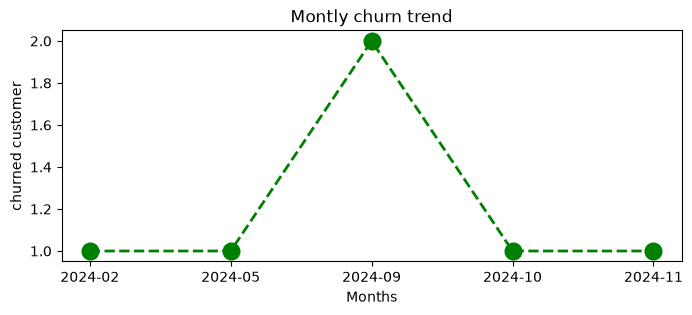

In [206]:
# 4.1 Monthly Churn Trend (Time Series KPI)
df_visual['cancellation_month'] = df_visual['cancellation_date'].dt.to_period('M')
churn_trend = (
    df_visual[df_visual['churn_flag'] == 1]
    .groupby('cancellation_month')
    .size()
    .sort_index()
)

plt.figure(figsize =(8,3))
plt.plot(churn_trend.index.astype(str),churn_trend.values, color='green', marker='o', linestyle='dashed',linewidth=2, markersize=12)
plt.title("Monthly Churn Trend")
plt.xlabel("Months")
plt.ylabel("Number of Churned Customers")

### Interpretation — Monthly Churn Trend

The line chart shows how many churned records fall in each cancellation month. Peaks may reflect seasonality, renewal timing, pricing changes, or support issues. Counts are not the same as monthly churn rates; rates require the number of customers at risk in each month as a denominator.

In [207]:
df_visual['cancellation_month'] = df_visual['cancellation_date'].dt.to_period('M')
df_visual[['cancellation_month','churn_flag']].nunique

<bound method DataFrame.nunique of    cancellation_month  churn_flag
0                 NaT           0
1             2024-09           1
2                 NaT           0
3                 NaT           0
4             2024-02           1
5                 NaT           0
6             2024-11           1
7                 NaT           0
8                 NaT           0
9                 NaT           0
10                NaT           0
11            2024-05           1
12                NaT           0
13            2024-10           1
14                NaT           0
15                NaT           0
16                NaT           0
17                NaT           0
18            2024-09           1
19                NaT           0
20                NaT           0>

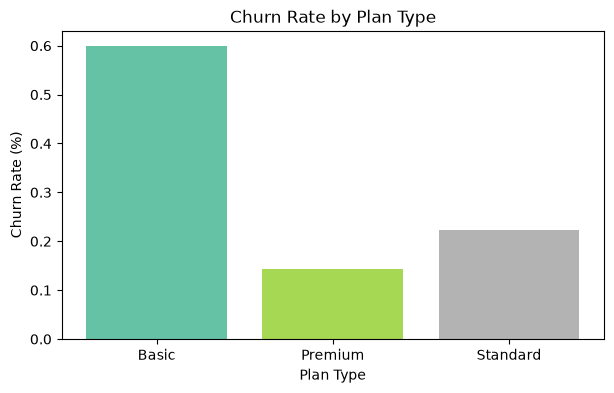

In [208]:
# 4.2 Churn Rate by Plan type
churn_plan = df_visual.groupby('plan_type')['churn_flag'].mean() * 100

plt.figure(figsize = (7,4))
colors = plt.cm.Set2(np.linspace(0, 1, len(churn_plan)))
plt.bar(churn_plan.index , churn_plan.values , color =colors)
plt.title("Churn Rate by Plan Type")
plt.xlabel('Plan Type')
plt.ylabel('Churn Rate (%)')
plt.show()

### Interpretation — Churn by Plan Type

Compare churn rates across plans, but also inspect the number of customers in each plan. A plan with high churn may warrant a review of pricing, benefits, customer expectations, or onboarding. Validate the pattern over time before making plan changes.

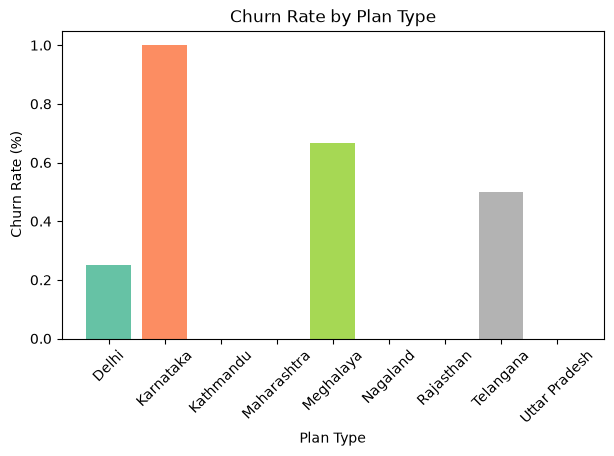

In [209]:
# 4.3 Churn by States
churn_state = df_visual.groupby('state')['churn_flag'].mean() * 100

plt.figure(figsize=(7,4))

colors = plt.cm.Set2(np.linspace(0, 1, len(churn_state)))
plt.bar(churn_state.index , churn_state.values , color =colors)
plt.title("Churn Rate by State")
plt.xlabel('State')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=45)
plt.show()

### Interpretation — Churn by State

The chart highlights geographic differences in the observed churn rate. Use it to identify states for deeper investigation, not to assume geography itself is the cause. Check sample sizes and compare plan mix, contract type, and support experience across states.

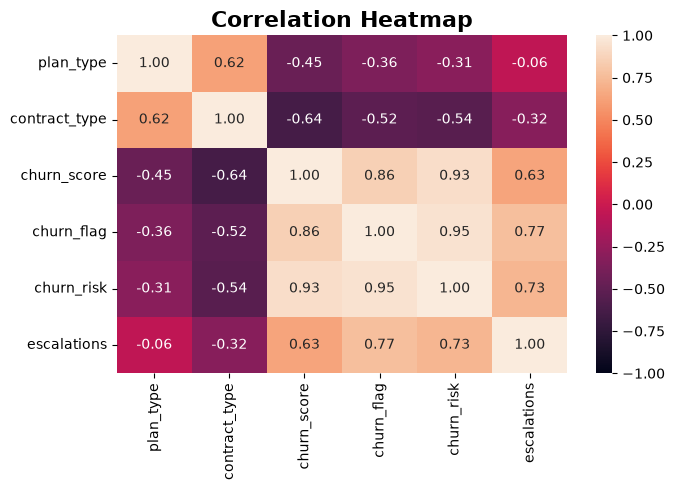

In [210]:

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Select the required columns
df_encoded = df_visual[
    ['plan_type', 'contract_type', 'churn_score',
     'churn_flag', 'churn_risk', 'escalations']
].copy()

# 2. Define the correct category order
order_mappings = {
    'plan_type': ['Basic', 'Standard', 'Premium'],
    'contract_type': ['Monthly', 'Annual'],
    'churn_risk': ['low', 'med', 'high']
}

# 3. Encode categorical columns in the specified order
for col, categories_order in order_mappings.items():
    df_encoded[col] = pd.Categorical(
        df_encoded[col],
        categories=categories_order,
        ordered=True
    ).codes

# 4. Convert Y/N escalations into numeric values
df_encoded['escalations'] = df_encoded['escalations'].replace({
    'Y': 1,
    'N': 0
})

# 5. Ensure every selected column is numeric
df_encoded = df_encoded.apply(pd.to_numeric, errors='coerce')

# 6. Calculate the correlation matrix
corr_matrix = df_encoded.corr(numeric_only=True)

# 7. Create the heatmap using the FIRST colour style
plt.figure(figsize=(7, 5))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='rocket',
    fmt='.2f',
    linewidths=0,
    center=0,
    vmin=-1,
    vmax=1,
    cbar=True
)

# 8. Add title and format labels
plt.title('Correlation Heatmap', fontsize=16, fontweight='bold')
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


   

In [211]:
print('plan_type :', df_visual['plan_type'].unique())
print('contract_type :', df_visual['contract_type'].unique())
print('churn_risk :', df_visual['churn_risk'].unique())

plan_type : <StringArray>
['Standard', 'Premium', 'Basic']
Length: 3, dtype: str
contract_type : <StringArray>
['Annual', 'Monthly']
Length: 2, dtype: str
churn_risk : <StringArray>
['low', 'high', 'med']
Length: 3, dtype: str


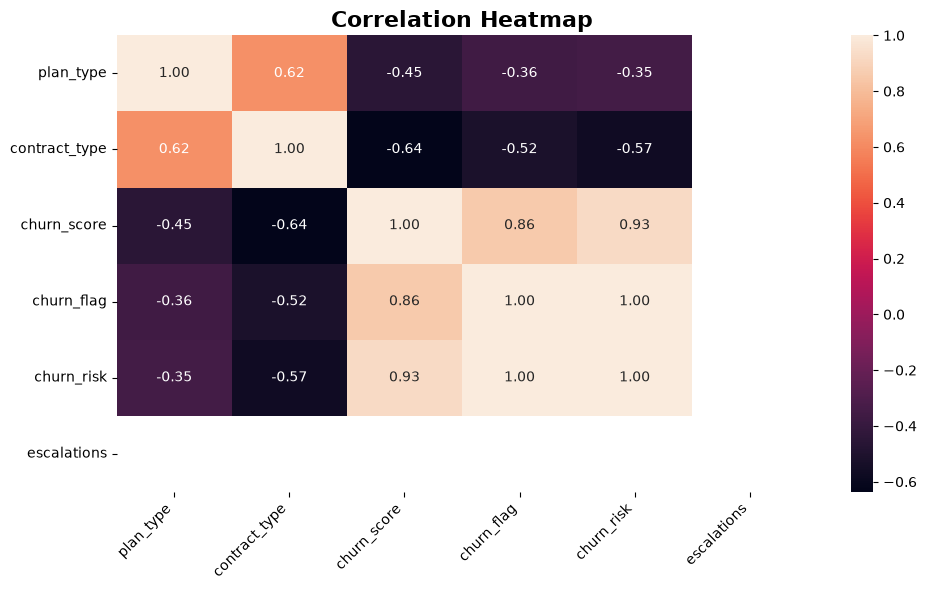

In [212]:
# Encode categorical columns correctly
df_encoded = df_visual[
    ['plan_type', 'contract_type', 'churn_score',
     'churn_flag', 'churn_risk', 'escalations']
].copy()

df_encoded['plan_type'] = df_encoded['plan_type'].map({
    'Basic': 0, 'Standard': 1, 'Premium': 2
})

df_encoded['contract_type'] = df_encoded['contract_type'].map({
    'Monthly': 0, 'Annual': 1
})

df_encoded['churn_risk'] = df_encoded['churn_risk'].map({
    'low': 0, 'medium': 1, 'mid': 1, 'high': 2
})

df_encoded['escalations'] = df_encoded['escalations'].map({
    'N': 0, 'Y': 1
})

# Plot heatmap in your preferred pink/orange style
plt.figure(figsize=(10, 6))
sns.heatmap(df_encoded.corr(), annot=True, cmap='rocket', fmt='.2f')
plt.title('Correlation Heatmap', fontsize=16, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

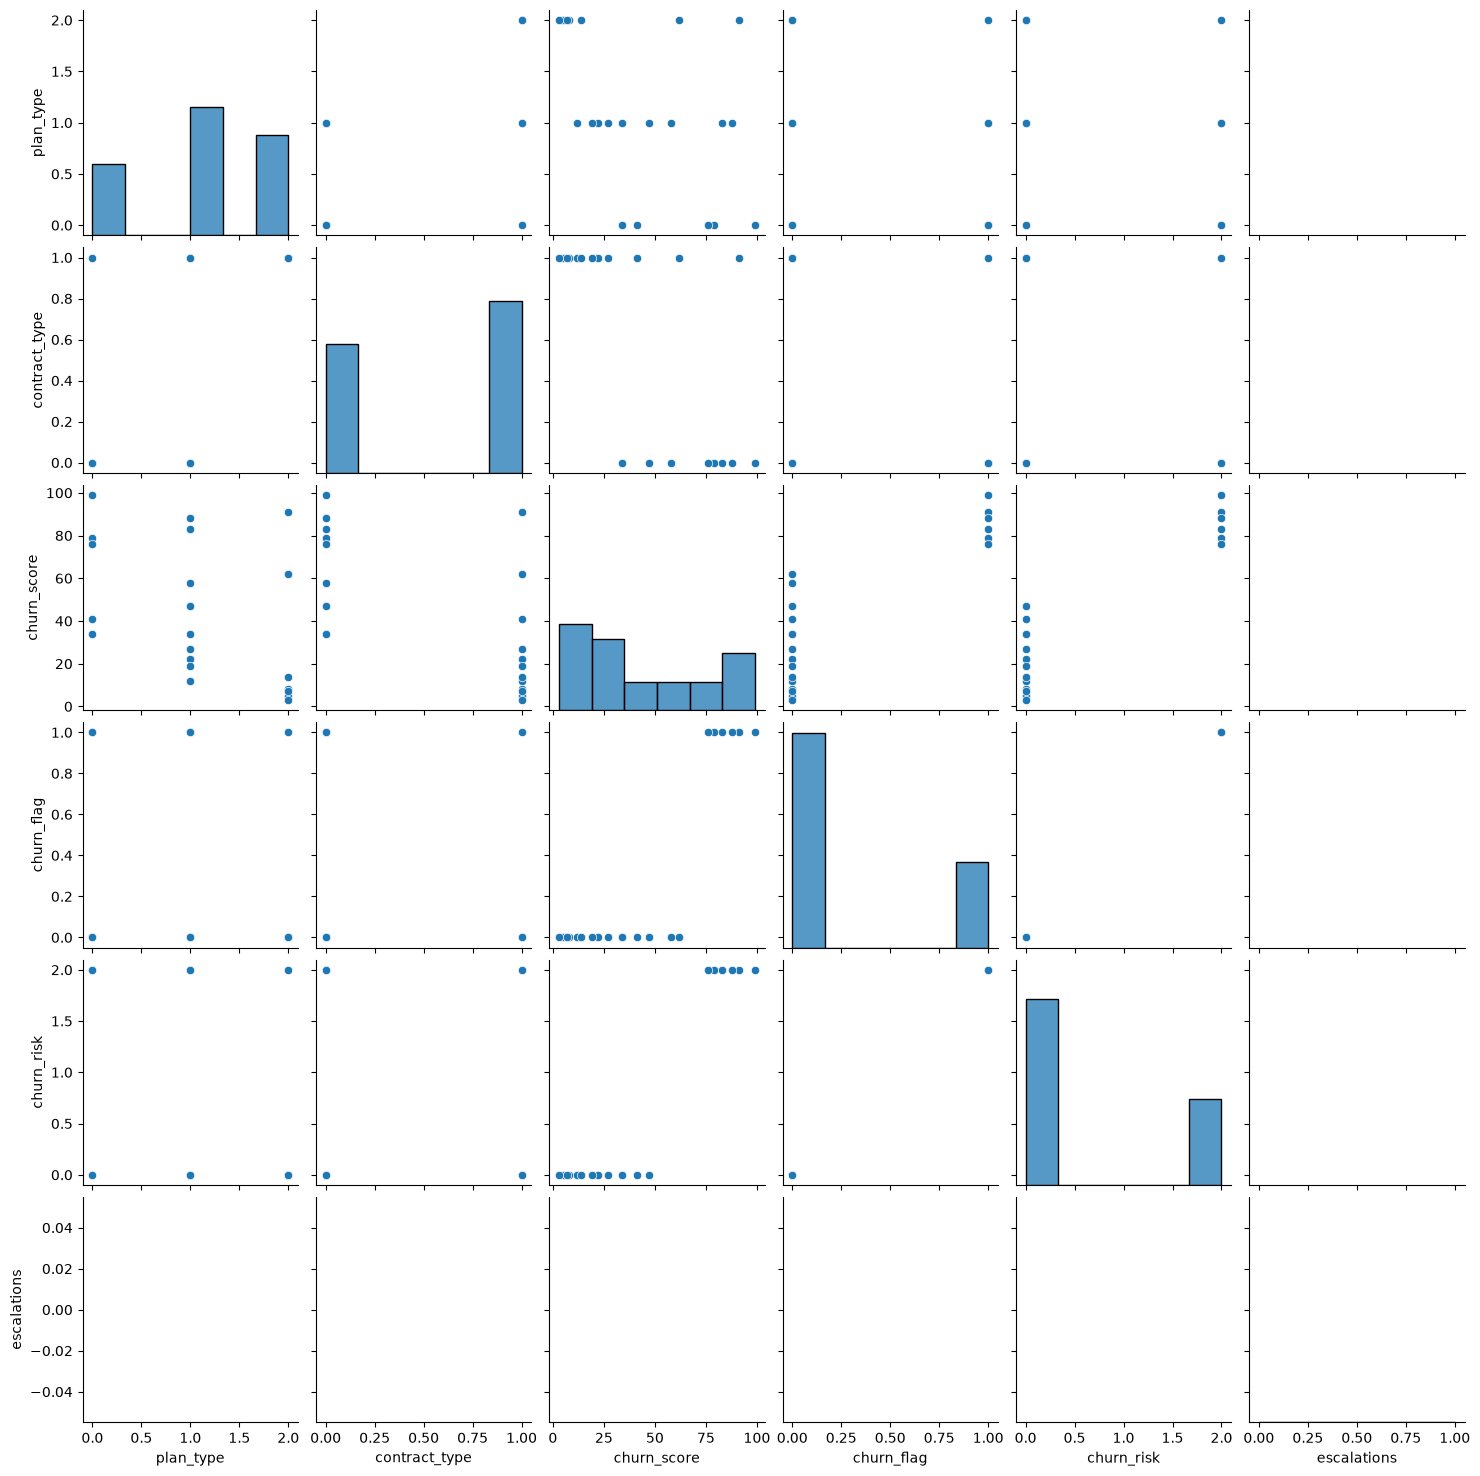

In [213]:
# pairplot - Plot pairwise relationships in a dataset
sns.pairplot(df_encoded)

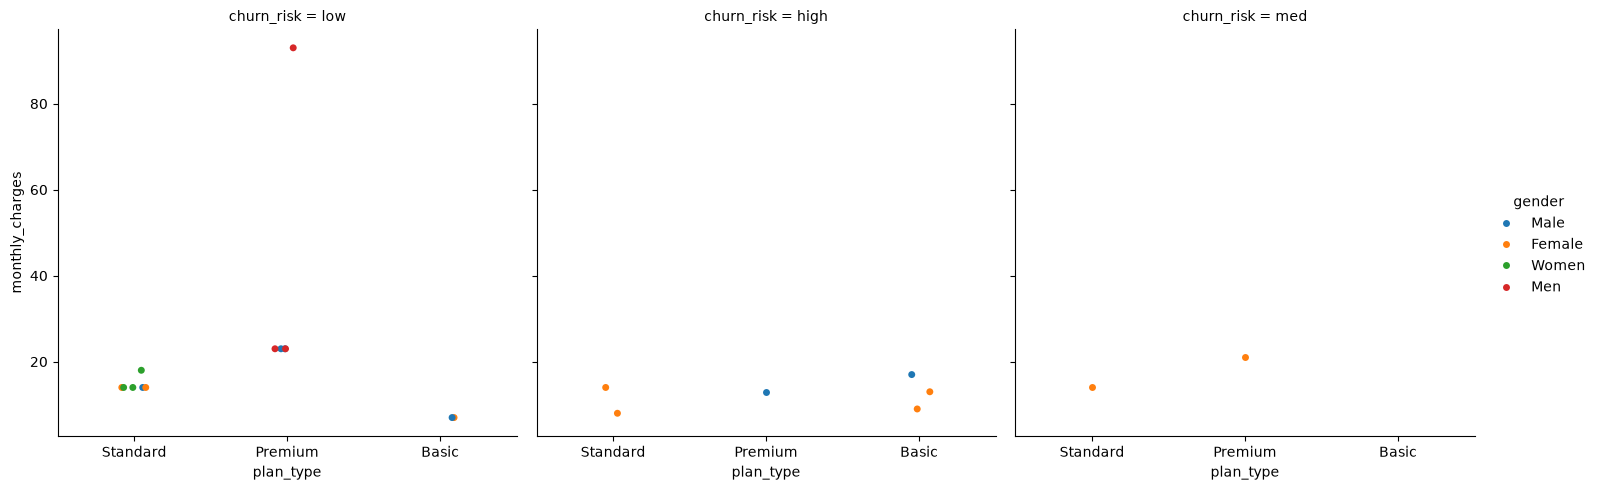

In [214]:
# catplt/Facegrid plot - multi-dim comparison

sns.catplot(data=df_visual,
    x='plan_type',
    y='monthly_charges',
    hue='gender',
    col='churn_risk')

### Interpretation — Monthly Charges by Plan, Gender, and Risk

This plot helps compare monthly charges across plan types, split by gender and churn-risk bucket. Look for meaningful differences in customer value or risk composition, but avoid interpreting demographic differences as causal. Confirm patterns with group sizes and appropriate fairness/privacy considerations.

### Pivot Table

In [215]:
# Pivot Table

pd.pivot_table(
    df_visual,
    index='plan_type',
    values='churn_flag',
    aggfunc = 'mean'
)

,churn_flag
plan_type,
Basic,0.600000
Premium,0.142857
Standard,0.222222


### Interpretation — Pivot Table by Plan

The pivot table gives the average churn flag for each plan, which is equivalent to the observed churn proportion when `churn_flag` is encoded as 0/1. Use it to compare plans, and pair the rate with customer counts so small groups are not over-interpreted.

In [216]:
# pivot table using multiple cols and agg type

pd.pivot_table(
    df_visual,
    index='plan_type',
    values=['monthly_charges', 'customerid', 'churn_flag'],
    aggfunc = {
        'monthly_charges' : 'sum',
        'customerid' : 'nunique',
        'churn_flag' : 'mean'
    }
)

,churn_flag,customerid,monthly_charges
plan_type,,,
Basic,0.600000,5,52.95
Premium,0.142857,7,218.93
Standard,0.222222,9,123.91


### Interpretation — Multi-Metric Pivot Table

This pivot table compares monthly charges, customer counts, and churn across plans. Review customer volume and charge totals together with churn rate: the segment with the highest churn rate is not always the segment with the greatest potential revenue impact.

# Key Findings & Actionable Recommendations

## Key findings to complete from the notebook outputs

- **Overall churn and retention:** Record the churn and retention percentages shown above, along with the date range and population represented by the database.
- **Customer segments:** Identify subscription sources, plans, and states with higher churn. Include the customer count for each segment so that small samples are not mistaken for reliable trends.
- **Customer value:** Use ARPU and the monthly charges associated with churned customers to understand potential exposure. Distinguish this estimate from confirmed revenue loss.
- **Support experience:** Compare complaint frequency, escalation rates, and satisfaction measures for active and churned customers, where those fields are available.
- **Risk-score usefulness:** Check whether the actual churn rate increases across the low-, medium-, and high-risk buckets before using them to prioritize outreach.

## Actionable recommendations

1. **Prioritize high-value customers at risk.** Review customers with elevated churn scores and higher monthly charges or customer lifetime value. Test targeted outreach or retention offers, and measure results against a comparable control group.
2. **Improve onboarding and early engagement.** If churn is concentrated among newer customers, introduce welcome check-ins, product education, and proactive support during the first 30–90 days.
3. **Close the support loop.** Proactively follow up on unresolved complaints and escalations. Track resolution time, customer satisfaction, and subsequent churn to see whether the process improves retention.
4. **Investigate acquisition-source quality.** If Referral or another source has elevated churn, validate the sample size and examine campaign messaging, customer expectations, and activation before changing acquisition investment.
5. **Review plans and contracts.** For plans or contract types with higher churn, investigate pricing clarity, feature usage, renewal timing, and whether customers can move to a better-fitting option.
6. **Monitor trends monthly.** Maintain a simple dashboard for churn rate, retention rate, monthly charges associated with churned customers, complaints, escalations, and churn by segment.
7. **Validate the existing churn score.** Compare score buckets with actual historical outcomes. Do not treat the score as a proven prediction until its ranking performance and limitations have been assessed.

## Limitations to mention in a portfolio

- These results describe the records in the available SQLite database and may not represent the full customer population.
- The analysis treats a non-null cancellation date as churn; confirm that this matches the business definition.
- Monthly cancellation counts are not monthly churn rates unless a customer-at-risk denominator is available for each month.
- Segment comparisons and correlations show associations, not causes.
- The existing churn score is analyzed here; this notebook does not train or validate a new machine-learning model.